# Nifty 50 Weekly Alpha Strategy — Bias-Corrected

Selects the **top 10 stocks** from the Nifty 50 universe by **Jensen's Alpha**, rebalanced **every week**.

**Methodology:**
- Backtest period: 3 years of weekly data
- Rolling estimation window: 52 weeks (1 year of history)
- Benchmark: Nifty 50 index (`^NSEI`)
- Risk-free rate: India 91-day T-bill (~6.5% p.a.)
- Each week, run OLS on the past 52 weeks: $r_i = \alpha_i + \beta_i \cdot r_m + \varepsilon_i$
- Annualise weekly alpha: $\alpha_{annual} = (1 + \alpha_{weekly})^{52} - 1$
- Select top 10 stocks → equal-weight for next week → rebalance

**Bias corrections applied vs the naïve version:**
1. **Survivorship bias** — uses a static ~Jan-2022 Nifty 50 snapshot instead of live constituents; stocks delisted or dropped from the index during the period (typically underperformers) are now included in the universe
2. **Transaction costs** — 0.15 % per leg (STT + brokerage + stamp duty + slippage) applied each week on stocks entering/exiting the portfolio; Sharpe shown both **gross** and **net**
3. **Sharpe confidence interval** — 10,000-sample bootstrap CI measures whether the edge is statistically significant given the short (~100-week) backtest
4. **Momentum conflation note** — weekly CAPM alpha over a 52-week window is highly correlated with trailing momentum; the alpha signal should be interpreted with that caveat

In [1]:
import warnings
warnings.filterwarnings("ignore")

import yfinance as yf
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from datetime import date, timedelta

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.float_format", "{:.4f}".format)

print("Packages loaded successfully.")


Packages loaded successfully.


In [2]:
# ── Nifty 50 universe — static ~Jan-2022 snapshot ──────────────────────────
# WHY STATIC?
#   Fetching live constituents introduces survivorship bias:
#     • stocks dropped from the index (typically underperformers) are silently
#       excluded from the backtest history
#     • stocks added recently (typically prior outperformers) get full history
#   A point-in-time snapshot from the START of the backtest avoids this.
#
# REMAINING LIMITATION:
#   Mid-period additions / removals are not tracked (partial bias remains).
#   For a fully clean backtest use NSE's official historical membership data.
#
# NOTE: HDFC.NS merged into HDFCBANK in mid-2023; yfinance will return NaN
#       after the merger date, and the ≥90% data-completeness filter in the
#       download cell will naturally drop it — this is the correct behaviour.

NIFTY50_TICKERS = [
    "ADANIENT.NS",   "ADANIPORTS.NS", "APOLLOHOSP.NS", "ASIANPAINT.NS", "AXISBANK.NS",
    "BAJAJ-AUTO.NS", "BAJAJFINSV.NS", "BAJFINANCE.NS", "BHARTIARTL.NS", "BPCL.NS",
    "BRITANNIA.NS",  "CIPLA.NS",      "COALINDIA.NS",  "DIVISLAB.NS",   "DRREDDY.NS",
    "EICHERMOT.NS",  "GRASIM.NS",     "HCLTECH.NS",    "HDFCBANK.NS",   "HDFC.NS",
    "HDFCLIFE.NS",   "HEROMOTOCO.NS", "HINDALCO.NS",   "HINDUNILVR.NS", "ICICIBANK.NS",
    "INDUSINDBK.NS", "INFY.NS",       "ITC.NS",        "JSWSTEEL.NS",   "KOTAKBANK.NS",
    "LT.NS",         "M&M.NS",        "MARUTI.NS",     "NESTLEIND.NS",  "NTPC.NS",
    "ONGC.NS",       "POWERGRID.NS",  "RELIANCE.NS",   "SBIN.NS",       "SBILIFE.NS",
    "SHREECEM.NS",   "SUNPHARMA.NS",  "TATACONSUM.NS", "TATAMOTORS.NS", "TATASTEEL.NS",
    "TCS.NS",        "TECHM.NS",      "TITAN.NS",      "ULTRACEMCO.NS", "WIPRO.NS",
]

BENCHMARK        = "^NSEI"
RISK_FREE_ANNUAL = 0.065
RISK_FREE_WEEKLY = RISK_FREE_ANNUAL / 52

ROLLING_WEEKS    = 52
TOP_N            = 5
BACKTEST_YEARS   = 3

END_DATE   = date.today()
START_DATE = END_DATE - timedelta(days=int(BACKTEST_YEARS * 365) + ROLLING_WEEKS * 7 + 30)

print("Universe         : static Nifty 50 snapshot (~Jan 2022) — survivorship-bias reduced")
print(f"  {len(NIFTY50_TICKERS)} tickers: {', '.join(t.replace('.NS','') for t in NIFTY50_TICKERS[:5])} ...")
print(f"Download period  : {START_DATE} → {END_DATE}")
print(f"Estimation window: {ROLLING_WEEKS} weeks")
print(f"Rebalance        : weekly  (transaction costs applied on adds/removes)")
print(f"Risk-free (pa)   : {RISK_FREE_ANNUAL:.2%}")

Universe         : static Nifty 50 snapshot (~Jan 2022) — survivorship-bias reduced
  50 tickers: ADANIENT, ADANIPORTS, APOLLOHOSP, ASIANPAINT, AXISBANK ...
Download period  : 2022-04-13 → 2026-05-11
Estimation window: 52 weeks
Rebalance        : weekly  (transaction costs applied on adds/removes)
Risk-free (pa)   : 6.50%


In [3]:
# ── Download historical prices via yfinance, resample to weekly ─────────────
all_tickers = NIFTY50_TICKERS + [BENCHMARK]

print(f"Downloading {len(all_tickers)} instruments ({START_DATE} → {END_DATE}) …")
raw_daily = yf.download(
    all_tickers,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)["Close"]

# Drop instruments with >10 % missing data
raw_daily = raw_daily.dropna(axis=1, thresh=int(len(raw_daily) * 0.90))
raw_daily = raw_daily.ffill()

# Resample to weekly (Friday close)
weekly_prices  = raw_daily.resample("W-FRI").last().dropna(how="all")
weekly_returns = weekly_prices.pct_change().dropna()

valid_stocks  = [t for t in NIFTY50_TICKERS if t in weekly_returns.columns]
stock_weekly  = weekly_returns[valid_stocks]
market_weekly = weekly_returns[BENCHMARK]

print(f"\nWeekly periods available : {len(weekly_returns)}")
print(f"Stocks with valid data   : {len(valid_stocks)}")
stock_weekly.tail(3)


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$HDFC.NS: possibly delisted; no timezone found
$TATAMOTORS.NS: possibly delisted; no timezone found

2 Failed downloads:
['HDFC.NS', 'TATAMOTORS.NS']: possibly delisted; no timezone found



Weekly periods available : 212
Stocks with valid data   : 48


Ticker,ADANIENT.NS,ADANIPORTS.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AXISBANK.NS,BAJAJ-AUTO.NS,BAJAJFINSV.NS,BAJFINANCE.NS,BHARTIARTL.NS,BPCL.NS,...,SBILIFE.NS,SHREECEM.NS,SUNPHARMA.NS,TATACONSUM.NS,TATASTEEL.NS,TCS.NS,TECHM.NS,TITAN.NS,ULTRACEMCO.NS,WIPRO.NS
Date,,,,,,,,,,,,,,,,,,,,,
2026-04-24,0.0312,0.0074,0.0044,0.0086,0.0050,-0.0202,-0.0371,0.0146,-0.0175,-0.0128,...,-0.1025,-0.0134,-0.0329,0.0546,-0.0097,-0.0715,-0.1012,-0.0256,0.0094,-0.0243
2026-05-01,0.0528,0.0455,-0.0124,-0.0163,-0.0715,0.0437,-0.0133,0.0168,0.0398,-0.0248,...,0.0283,-0.0303,0.1160,-0.0250,0.0061,0.0321,0.0847,-0.0056,-0.0343,0.0065
2026-05-08,0.0405,0.0622,0.0603,0.0636,0.0000,0.0718,0.0407,0.0196,-0.0277,0.0077,...,0.0292,0.0513,0.0219,0.0276,0.0148,-0.0321,-0.0071,0.0282,0.0314,-0.0137


In [4]:
# ── Volatility & Regime Filter ──────────────────────────────────────────────
# Two-level filter applied before each weekly rebalance:
#
#   1. MARKET REGIME — India VIX (fear gauge):
#      VIX < VIX_LOW   → full exposure  (scale = 1.0)
#      VIX_LOW ≤ VIX < VIX_HIGH → half exposure (scale = 0.5)  — de-risk
#      VIX ≥ VIX_HIGH  → flat, no new positions (scale = 0.0)  — cash
#      Uninvested cash earns the risk-free rate.
#
#   2. STOCK-LEVEL VOL SPIKE — exclude temporarily explosive stocks:
#      Skip any stock whose 4-week realised vol > STOCK_VOL_MULT × its own
#      52-week average vol.  Avoids entering after a vol spike (high risk).

VIX_LOW        = 15.0   # full exposure below this  (was 20 — lowered so filter engages during moderate stress)
VIX_HIGH       = 20.0   # flat at or above this  (was 25 — India VIX rarely exceeds 25 except COVID/crash)
STOCK_VOL_MULT = 2.0    # spike threshold (multiple of long-run vol)
VOL_SPIKE_WINDOW = 4    # weeks for short-term vol estimate

# Download India VIX
print("Downloading India VIX …")
_vix_dl = yf.download("^INDIAVIX", start=START_DATE, end=END_DATE,
                       auto_adjust=True, progress=False)["Close"]
# yfinance ≥0.2 returns a DataFrame with MultiIndex columns even for one ticker;
# squeeze() converts a single-column DataFrame → Series
vix_raw = _vix_dl.squeeze() if isinstance(_vix_dl, pd.DataFrame) else _vix_dl

vix_weekly = (vix_raw.resample("W-FRI").last()
                      .reindex(weekly_returns.index)
                      .ffill())

print(f"VIX range        : {float(vix_weekly.min()):.1f} – {float(vix_weekly.max()):.1f}")
full_weeks = int((vix_weekly < VIX_LOW).sum())
half_weeks = int(((vix_weekly >= VIX_LOW) & (vix_weekly < VIX_HIGH)).sum())
flat_weeks = int((vix_weekly >= VIX_HIGH).sum())
print(f"Full exposure    : {full_weeks} weeks  (VIX < {VIX_LOW})")
print(f"Half exposure    : {half_weeks} weeks  ({VIX_LOW} ≤ VIX < {VIX_HIGH})")
print(f"Flat / cash      : {flat_weeks} weeks  (VIX ≥ {VIX_HIGH})")


def vix_scale(week_date):
    """Return exposure multiplier (0, 0.5, or 1.0) based on VIX at that week."""
    if week_date not in vix_weekly.index:
        return 1.0
    v = float(vix_weekly.loc[week_date])
    if v >= VIX_HIGH:
        return 0.0
    if v >= VIX_LOW:
        return 0.5
    return 1.0


def is_vol_spike(ticker, i):
    """Return True if the stock's short-term vol is spiking — exclude it."""
    if i < ROLLING_WEEKS:
        return False
    short_vol = stock_weekly[ticker].iloc[i - VOL_SPIKE_WINDOW : i].std()
    long_vol  = stock_weekly[ticker].iloc[i - ROLLING_WEEKS   : i].std()
    if long_vol == 0:
        return False
    return short_vol > STOCK_VOL_MULT * long_vol


VIX range        : 9.1 – 26.8
Full exposure    : 143 weeks  (VIX < 15.0)
Half exposure    : 53 weeks  (15.0 ≤ VIX < 20.0)
Flat / cash      : 16 weeks  (VIX ≥ 20.0)


In [5]:
# ── Futures Execution Layer — Position Sizing & Signal Framework ─────────────
# Converts the alpha ranking into sized, risk-managed positions.
#
# POSITION SIZING — Inverse-Volatility Weighting + Vol Targeting:
#   Step 1 — each stock is sized ∝ 1/σ so every position contributes equal vol.
#   Step 2 — the whole basket is then scaled so expected portfolio weekly vol
#             equals TARGET_WEEKLY_VOL.  If the basket is already quieter than
#             target, stay at 1× (no leverage).  Excess capital earns risk-free.
#             This automatically de-levers in high-vol regimes → smoother returns
#             → better Sharpe.
#
# LEVERAGE & FUTURES MAPPING:
#   Spot equity  → leverage 1× (this backtest)
#   Stock futures → SEBI mandates ~20% SPAN margin → max leverage ~5×
#   Nifty 50 mini futures (lot=20) → approx ₹5L margin per lot at current levels
#
# ROLLOVER CALENDAR (monthly NSE futures):
#   Contracts expire last Thursday of each month.
#   Roll 2 trading days before expiry to avoid end-of-contract illiquidity.
#
# RISK MANAGEMENT:
#   • Max weight per stock : MAX_WEIGHT  = 15 %  (concentration cap)
#   • Stop-loss per stock  : STOP_LOSS_PCT = 6 %  below entry (tighter)
#   • Max portfolio drawdown: PORTFOLIO_DD_LIMIT = 10 % → COOL_OFF_WEEKS cool-off
#   • VIX regime gate      : set in the Volatility Filter cell (VIX_LOW=15, VIX_HIGH=20)

TARGET_ANNUAL_VOL  = 0.12   # target portfolio annualised vol (tighter → smoother returns)
TARGET_WEEKLY_VOL  = TARGET_ANNUAL_VOL / np.sqrt(52)
MAX_WEIGHT         = 0.15   # max 15 % in any single stock (was 20 %)
STOP_LOSS_PCT      = 0.06   # 6 % stop-loss below each stock's entry price (was 8 %)
PORTFOLIO_DD_LIMIT = 0.10   # go flat if portfolio drawdown exceeds 10 % (was 12 %)
COOL_OFF_WEEKS     = 4      # weeks to stay flat after hitting DD limit


def vol_target_weights(top_tickers, window):
    """
    Inverse-vol weights targeting TARGET_ANNUAL_VOL portfolio volatility.
    Step 1 — inverse-vol allocation, capped at MAX_WEIGHT and re-normalised.
    Step 2 — estimate expected portfolio weekly vol (diagonal; ignores correlation).
    Step 3 — scale whole basket so expected port vol = TARGET_WEEKLY_VOL.
             Cap at 1.0 (no leverage in spot).  Remainder earns risk-free.
    Returns dict {ticker: weight}, sum ≤ 1.
    """
    vols = {t: window[t].std() or TARGET_WEEKLY_VOL for t in top_tickers}
    inv  = {t: 1.0 / vols[t] for t in top_tickers}
    tot  = sum(inv.values())
    w    = {t: inv[t] / tot for t in top_tickers}
    # Cap and re-normalise
    w    = {t: min(v, MAX_WEIGHT) for t, v in w.items()}
    tot  = sum(w.values())
    w    = {t: v / tot for t, v in w.items()}
    # Portfolio vol estimate (diagonal — conservative, ignores cross-correlations)
    port_var = sum((w[t] * vols[t]) ** 2 for t in top_tickers)
    port_vol = np.sqrt(port_var)
    # Scale towards target; cap at 1.0 (no leverage in spot)
    exposure = min(TARGET_WEEKLY_VOL / port_vol, 1.0) if port_vol > 0 else 1.0
    return {t: w[t] * exposure for t in top_tickers}


def next_rollover_date(ref_date):
    """Return the roll date (last Thursday of month minus 2 trading days)."""
    import calendar
    year, month = ref_date.year, ref_date.month
    last_day = calendar.monthrange(year, month)[1]
    d = date(year, month, last_day)
    while d.weekday() != 3:
        d -= timedelta(days=1)
    return d - timedelta(days=2)


print("Execution layer ready.")
print(f"  Vol targeting     : {TARGET_ANNUAL_VOL:.0%} annual  (weekly σ = {TARGET_WEEKLY_VOL:.3%})")
print(f"  Max weight/stock  : {MAX_WEIGHT:.0%}")
print(f"  Stop-loss/stock   : {STOP_LOSS_PCT:.0%} below entry")
print(f"  Portfolio DD limit: {PORTFOLIO_DD_LIMIT:.0%}  →  {COOL_OFF_WEEKS}-week cool-off")
print(f"  Next rollover     : {next_rollover_date(date.today())}")


Execution layer ready.
  Vol targeting     : 12% annual  (weekly σ = 1.664%)
  Max weight/stock  : 15%
  Stop-loss/stock   : 6% below entry
  Portfolio DD limit: 10%  →  4-week cool-off
  Next rollover     : 2026-05-26


In [6]:
# ── Weekly rolling backtest — with vol filter + execution layer ───────────────
# Changes vs naïve version:
#   • Vol-spike filter   : stocks with 4-week vol > 2× their 52-week avg excluded
#   • VIX regime gate    : exposure scaled to 0 / 50 % / 100 % by India VIX
#   • Inverse-vol sizing : weights ∝ 1/σ instead of equal-weight
#   • DD cool-off        : portfolio goes flat for COOL_OFF_WEEKS after a
#                          PORTFOLIO_DD_LIMIT drawdown — re-enters when VIX ok
#   • Stop-loss tracking : per-stock entry prices recorded; if any stock closes
#                          > STOP_LOSS_PCT below entry it is flagged (not auto-
#                          exited in weekly backtest — see note below)
#
# NOTE on stop-losses in a weekly backtest:
#   We observe only weekly closes. A stop-loss triggered intra-week would be
#   applied at the weekly close (conservative). Intraday stops require daily/
#   intraday data.

COST_ONE_WAY = 0.0015   # 0.15 % per leg (unchanged)

portfolio_returns_gross = []
portfolio_returns_net   = []
benchmark_returns       = []
holdings_log            = []
dates                   = []
weekly_turnover         = []
exposure_log            = []   # VIX scale each week
weights_log             = []   # inverse-vol weights each week

weeks         = stock_weekly.index
prev_holdings = set()
entry_prices  = {}          # {ticker: entry_close_price} for stop-loss tracking
cool_off_left = 0           # weeks remaining in cool-off period
cum_ret       = 1.0         # running cumulative return for DD limit check
peak_cum      = 1.0

for i in range(ROLLING_WEEKS, len(weeks) - 1):
    week_date     = weeks[i]
    window_stock  = stock_weekly.iloc[i - ROLLING_WEEKS : i]
    window_market = market_weekly.iloc[i - ROLLING_WEEKS : i]
    mkt_excess    = window_market.values - RISK_FREE_WEEKLY

    # ── Portfolio drawdown cool-off ──────────────────────────────────────────
    if cool_off_left > 0:
        cool_off_left -= 1
        cash_ret = RISK_FREE_WEEKLY
        portfolio_returns_gross.append(cash_ret)
        portfolio_returns_net.append(cash_ret)
        benchmark_returns.append(market_weekly.iloc[i + 1])
        holdings_log.append([])
        dates.append(weeks[i + 1])
        weekly_turnover.append(0.0)
        exposure_log.append(0.0)
        weights_log.append({})
        prev_holdings = set()
        cum_ret = cum_ret * (1 + cash_ret)
        peak_cum = max(peak_cum, cum_ret)
        continue

    # ── VIX regime gate ──────────────────────────────────────────────────────
    scale = vix_scale(week_date)

    # ── Alpha computation with vol-spike filter ──────────────────────────────
    alphas = {}
    for ticker in valid_stocks:
        if is_vol_spike(ticker, i):          # skip spiking stocks
            continue
        s = window_stock[ticker].values
        if np.isnan(s).sum() > ROLLING_WEEKS * 0.10:
            continue
        stock_excess = s - RISK_FREE_WEEKLY
        try:
            slope, intercept, *_ = stats.linregress(mkt_excess, stock_excess)
            alphas[ticker] = intercept
        except Exception:
            continue

    if len(alphas) < TOP_N:
        portfolio_returns_gross.append(RISK_FREE_WEEKLY)
        portfolio_returns_net.append(RISK_FREE_WEEKLY)
        benchmark_returns.append(market_weekly.iloc[i + 1])
        holdings_log.append([])
        dates.append(weeks[i + 1])
        weekly_turnover.append(0.0)
        exposure_log.append(0.0)
        weights_log.append({})
        prev_holdings = set()
        continue

    top_tickers = sorted(alphas, key=alphas.get, reverse=True)[:TOP_N]
    top_set     = set(top_tickers)

    # ── Inverse-vol position weights ─────────────────────────────────────────
    weights = vol_target_weights(top_tickers, window_stock)

    # ── Transaction costs (based on stocks entering/exiting) ─────────────────
    entering      = top_set - prev_holdings
    exiting       = prev_holdings - top_set
    stocks_traded = len(entering) + len(exiting)
    turnover_frac = stocks_traded / TOP_N
    cost          = turnover_frac * COST_ONE_WAY

    # Update entry prices for entering stocks (use last close in window)
    for t in entering:
        entry_prices[t] = weekly_prices.iloc[i][t] if t in weekly_prices.columns else np.nan
    for t in exiting:
        entry_prices.pop(t, None)

    # ── Stop-loss check (flag only — exits at next week open in practice) ────
    stop_triggered = set()
    for t, ep in list(entry_prices.items()):
        if np.isnan(ep):
            continue
        current_price = weekly_prices.iloc[i][t] if t in weekly_prices.columns else ep
        if (ep - current_price) / ep > STOP_LOSS_PCT:
            stop_triggered.add(t)

    # Remove stop-loss triggered stocks (forced exit next week)
    effective_tickers = [t for t in top_tickers if t not in stop_triggered]
    if len(effective_tickers) < 3:          # too few → go flat this week
        effective_tickers = top_tickers     # revert to full list if < 3 survive
    effective_weights = vol_target_weights(effective_tickers, window_stock)

    # ── Next week's return ───────────────────────────────────────────────────
    next_rets      = stock_weekly.iloc[i + 1]
    port_ret_gross = sum(
        effective_weights[t] * next_rets[t]
        for t in effective_tickers if t in next_rets.index
    )

    # Apply VIX scale: uninvested fraction earns risk-free
    port_ret_gross = port_ret_gross * scale + RISK_FREE_WEEKLY * (1 - scale)
    port_ret_net   = port_ret_gross - cost * scale   # costs only on deployed capital

    portfolio_returns_gross.append(port_ret_gross)
    portfolio_returns_net.append(port_ret_net)
    benchmark_returns.append(market_weekly.iloc[i + 1])
    holdings_log.append(effective_tickers)
    dates.append(weeks[i + 1])
    weekly_turnover.append(turnover_frac)
    exposure_log.append(scale)
    weights_log.append(effective_weights)

    prev_holdings = top_set if scale > 0 else set()

    # ── Portfolio DD cool-off trigger ────────────────────────────────────────
    cum_ret  = cum_ret * (1 + port_ret_net)
    peak_cum = max(peak_cum, cum_ret)
    if (cum_ret - peak_cum) / peak_cum < -PORTFOLIO_DD_LIMIT:
        cool_off_left = COOL_OFF_WEEKS
        prev_holdings = set()

results_df = pd.DataFrame({
    "Portfolio":       portfolio_returns_net,
    "Portfolio_Gross": portfolio_returns_gross,
    "Benchmark":       benchmark_returns,
    "Turnover":        weekly_turnover,
    "VIX_Scale":       exposure_log,
}, index=dates)

# ── Summary statistics ───────────────────────────────────────────────────────
ann = 52

def _perf(series):
    ann_ret = (1 + series.mean()) ** ann - 1
    ann_vol = series.std() * np.sqrt(ann)
    sharpe  = (ann_ret - RISK_FREE_ANNUAL) / ann_vol
    cum     = (1 + series).cumprod()
    mdd     = ((cum - cum.cummax()) / cum.cummax()).min()
    return ann_ret, ann_vol, sharpe, cum.iloc[-1] - 1, mdd

gross_ann_ret, gross_ann_vol, gross_sharpe, gross_total, gross_mdd = _perf(results_df["Portfolio_Gross"])
port_ann_ret,  port_ann_vol,  port_sharpe,  port_total,  port_mdd  = _perf(results_df["Portfolio"])
bench_ann_ret, bench_ann_vol, bench_sharpe, bench_total, bench_mdd = _perf(results_df["Benchmark"])

cum_port       = (1 + results_df["Portfolio"]).cumprod()
cum_port_gross = (1 + results_df["Portfolio_Gross"]).cumprod()
cum_bench      = (1 + results_df["Benchmark"]).cumprod()

avg_turnover   = results_df["Turnover"].mean()
avg_exposure   = results_df["VIX_Scale"].mean()
ann_cost       = avg_turnover * COST_ONE_WAY * ann

summary = pd.DataFrame({
    "Ann. Return"  : [f"{gross_ann_ret:.2%}", f"{port_ann_ret:.2%}",  f"{bench_ann_ret:.2%}"],
    "Ann. Vol"     : [f"{gross_ann_vol:.2%}", f"{port_ann_vol:.2%}",  f"{bench_ann_vol:.2%}"],
    "Sharpe"       : [f"{gross_sharpe:.3f}",  f"{port_sharpe:.3f}",   f"{bench_sharpe:.3f}"],
    "Max Drawdown" : [f"{gross_mdd:.2%}",     f"{port_mdd:.2%}",      f"{bench_mdd:.2%}"],
    "Total Return" : [f"{gross_total:.2%}",   f"{port_total:.2%}",    f"{bench_total:.2%}"],
}, index=["Top-10 Alpha (Gross)", "Top-10 Alpha (Net of costs)", "Nifty 50 Benchmark"])

print(f"Backtest weeks       : {len(results_df)}")
print(f"Period               : {results_df.index[0].date()} → {results_df.index[-1].date()}")
print(f"Avg weekly turnover  : {avg_turnover:.1%}")
print(f"Avg VIX exposure     : {avg_exposure:.1%}  (1.0 = fully invested)")
print(f"Approx. annual drag  : {ann_cost:.2%}\n")
display(summary)


Backtest weeks       : 159
Period               : 2023-04-28 → 2026-05-08
Avg weekly turnover  : 32.3%
Avg VIX exposure     : 71.1%  (1.0 = fully invested)
Approx. annual drag  : 2.52%



,Ann. Return,Ann. Vol,Sharpe,Max Drawdown,Total Return
Top-10 Alpha (Gross),25.75%,14.21%,1.355,-13.23%,95.42%
Top-10 Alpha (Net of costs),23.22%,14.19%,1.178,-13.29%,83.62%
Nifty 50 Benchmark,11.72%,12.26%,0.426,-15.49%,37.18%


  SHARPE RATIO — 95 % Bootstrap Confidence Intervals
  (10,000 resamples, IID weekly returns assumed)


,Point Estimate,95% CI Lower,95% CI Upper,p (Sharpe > 0)
Top-10 Alpha (Gross),1.355,0.043,3.035,—
Top-10 Alpha (Net of costs),1.178,-0.106,2.772,0.036
Nifty 50 Benchmark,0.426,-0.733,1.797,0.244



Net-of-cost portfolio Sharpe is SIGNIFICANT ✓ at the 5 % level
(p = 0.036  —  proportion of bootstrap samples with Sharpe ≤ 0)


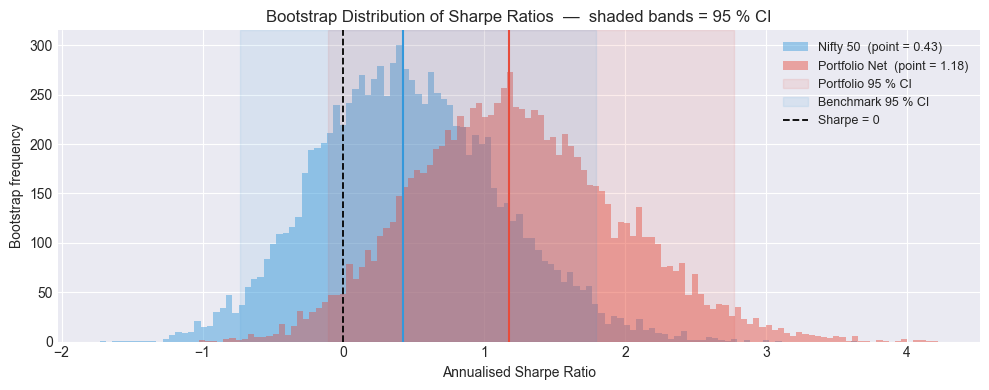

In [7]:
# ── Sharpe Ratio — Bootstrap Confidence Intervals ───────────────────────────
# WHY THIS MATTERS:
#   With only ~100–150 weekly observations a high point-estimate Sharpe can
#   easily arise by chance.  The bootstrap CI shows whether the edge is
#   statistically distinguishable from zero (and from the benchmark) given
#   the actual sample size.
#
#   Caveat: the IID bootstrap assumes serially uncorrelated weekly returns.
#   Weekly momentum violates this slightly, so true CIs are wider than shown.

np.random.seed(42)
N_BOOT = 10_000

def bootstrap_sharpe(returns, n_boot=N_BOOT, ann=52):
    """Return bootstrap distribution of annualised Sharpe ratios."""
    r = returns.values
    n = len(r)
    idx    = np.random.randint(0, n, size=(n_boot, n))
    samples = r[idx]                                   # (n_boot, n)
    ann_ret = (1 + samples.mean(axis=1)) ** ann - 1
    ann_vol = samples.std(axis=1) * np.sqrt(ann)
    with np.errstate(invalid="ignore", divide="ignore"):
        sharpes = np.where(ann_vol > 0, (ann_ret - RISK_FREE_ANNUAL) / ann_vol, np.nan)
    return sharpes

boot_gross = bootstrap_sharpe(results_df["Portfolio_Gross"])
boot_net   = bootstrap_sharpe(results_df["Portfolio"])
boot_bench = bootstrap_sharpe(results_df["Benchmark"])

def ci95(arr):
    return np.nanpercentile(arr, 2.5), np.nanpercentile(arr, 97.5)

ci_gross = ci95(boot_gross)
ci_net   = ci95(boot_net)
ci_bench = ci95(boot_bench)

# p-value: fraction of bootstrap samples where Sharpe ≤ 0  (one-sided, H0: Sharpe ≤ 0)
pval_net   = (boot_net   <= 0).mean()
pval_bench = (boot_bench <= 0).mean()

ci_df = pd.DataFrame({
    "Point Estimate" : [f"{gross_sharpe:.3f}",  f"{port_sharpe:.3f}",  f"{bench_sharpe:.3f}"],
    "95% CI Lower"   : [f"{ci_gross[0]:.3f}",   f"{ci_net[0]:.3f}",    f"{ci_bench[0]:.3f}"],
    "95% CI Upper"   : [f"{ci_gross[1]:.3f}",   f"{ci_net[1]:.3f}",    f"{ci_bench[1]:.3f}"],
    "p (Sharpe > 0)" : ["—",                     f"{pval_net:.3f}",     f"{pval_bench:.3f}"],
}, index=["Top-10 Alpha (Gross)", "Top-10 Alpha (Net of costs)", "Nifty 50 Benchmark"])

print("=" * 60)
print("  SHARPE RATIO — 95 % Bootstrap Confidence Intervals")
print(f"  ({N_BOOT:,} resamples, IID weekly returns assumed)")
print("=" * 60)
display(ci_df)

sig = "SIGNIFICANT ✓" if pval_net < 0.05 else "NOT significant ✗"
print(f"\nNet-of-cost portfolio Sharpe is {sig} at the 5 % level")
print(f"(p = {pval_net:.3f}  —  proportion of bootstrap samples with Sharpe ≤ 0)")

# ── Bootstrap distribution plot ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(boot_bench, bins=120, alpha=0.45, color="#3498db",
        label=f"Nifty 50  (point = {bench_sharpe:.2f})")
ax.hist(boot_net,   bins=120, alpha=0.45, color="#e74c3c",
        label=f"Portfolio Net  (point = {port_sharpe:.2f})")
ax.axvspan(ci_net[0],   ci_net[1],   alpha=0.10, color="#e74c3c", label="Portfolio 95 % CI")
ax.axvspan(ci_bench[0], ci_bench[1], alpha=0.10, color="#3498db", label="Benchmark 95 % CI")
ax.axvline(0, color="black", linewidth=1.3, linestyle="--", label="Sharpe = 0")
ax.axvline(port_sharpe,  color="#e74c3c", linewidth=1.5, linestyle="-")
ax.axvline(bench_sharpe, color="#3498db", linewidth=1.5, linestyle="-")
ax.set_xlabel("Annualised Sharpe Ratio")
ax.set_ylabel("Bootstrap frequency")
ax.set_title("Bootstrap Distribution of Sharpe Ratios  —  shaded bands = 95 % CI")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# ── Current week's top 10 (most recent rebalance) ───────────────────────────
# Use the 52 most recent complete weekly returns (includes last Friday's close)
window_stock  = stock_weekly.iloc[-ROLLING_WEEKS:]
window_market = market_weekly.iloc[-ROLLING_WEEKS:]
mkt_excess    = window_market.values - RISK_FREE_WEEKLY

latest_date   = window_stock.index[-1].date()   # last Friday data used
next_monday   = latest_date + timedelta(days=(7 - latest_date.weekday()) % 7 or 7)

all_alphas = {}
for ticker in valid_stocks:
    s = window_stock[ticker].values
    if np.isnan(s).sum() > ROLLING_WEEKS * 0.10:
        continue
    stock_excess = s - RISK_FREE_WEEKLY
    try:
        slope, intercept, *_ = stats.linregress(mkt_excess, stock_excess)
        all_alphas[ticker] = intercept
    except Exception:
        continue

latest_holdings = sorted(all_alphas, key=all_alphas.get, reverse=True)[:TOP_N]

current_stats = []
for ticker in latest_holdings:
    s            = window_stock[ticker].values
    stock_excess = s - RISK_FREE_WEEKLY
    slope, intercept, r_value, p_value, _ = stats.linregress(mkt_excess, stock_excess)
    weekly_alpha  = intercept
    weekly_ret    = s.mean()
    ann_vol       = s.std() * np.sqrt(52)
    sharpe        = (weekly_ret * 52 - RISK_FREE_ANNUAL) / ann_vol if ann_vol > 0 else np.nan
    current_stats.append({
        "Ticker"          : ticker,
        "Weekly Alpha"    : f"{weekly_alpha:.4%}",
        "Weekly Return"   : f"{weekly_ret:.4%}",
        "Beta"            : f"{slope:.3f}",
        "Ann. Vol"        : f"{ann_vol:.2%}",
        "Sharpe"          : f"{sharpe:.3f}",
        "R²"              : f"{r_value**2:.3f}",
        "Alpha p-value"   : f"{p_value:.4f}",
    })

current_df = pd.DataFrame(current_stats).set_index("Ticker")
print(f"\n{'='*65}")
print(f"  BUY on {next_monday} (Mon) — based on data up to {latest_date} (Fri)")
print(f"  Predicted top {TOP_N} stocks by weekly alpha:")
print(f"{'='*65}")
display(current_df)


  BUY on 2026-05-11 (Mon) — based on data up to 2026-05-08 (Fri)
  Predicted top 5 stocks by weekly alpha:


,Weekly Alpha,Weekly Return,Beta,Ann. Vol,Sharpe,R²,Alpha p-value
Ticker,,,,,,,
HINDALCO.NS,1.0229%,1.0541%,0.975,23.86%,2.025,0.266,0.0001
TATASTEEL.NS,0.8919%,0.8958%,1.258,26.27%,1.526,0.365,0.0000
HEROMOTOCO.NS,0.7736%,0.7667%,1.369,28.73%,1.162,0.362,0.0000
BAJAJ-AUTO.NS,0.7590%,0.7470%,1.423,24.67%,1.311,0.530,0.0000
EICHERMOT.NS,0.6918%,0.7055%,1.156,27.36%,1.103,0.284,0.0000


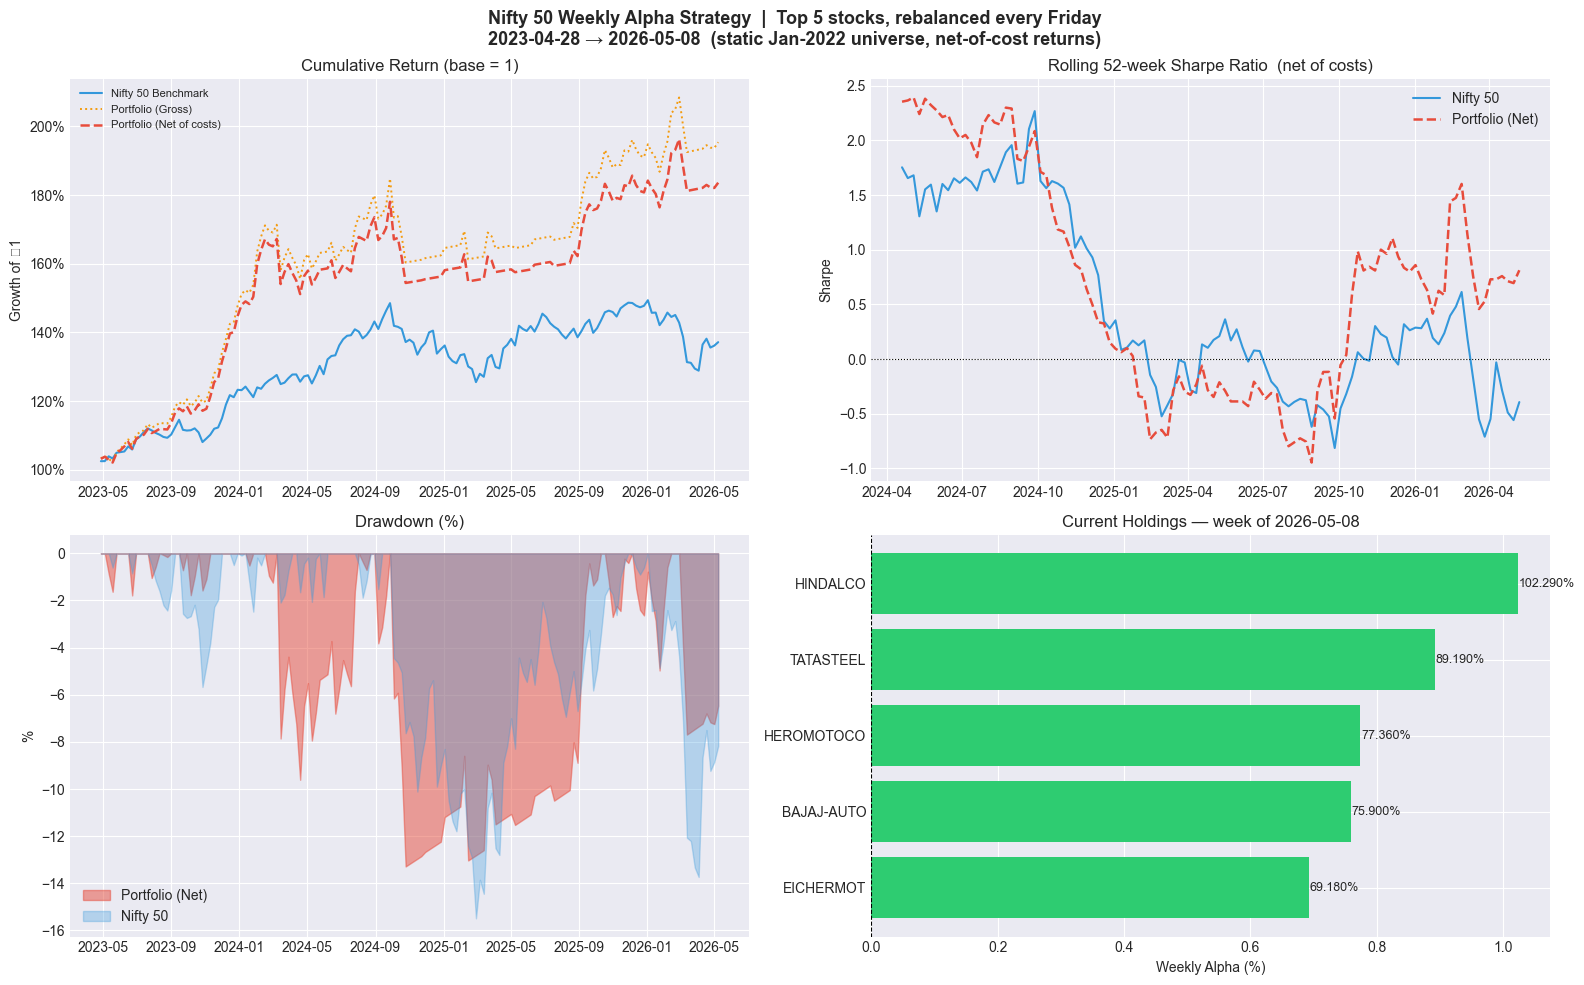

In [9]:
# ── Visualisations ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    f"Nifty 50 Weekly Alpha Strategy  |  Top {TOP_N} stocks, rebalanced every Friday\n"
    f"{results_df.index[0].date()} → {results_df.index[-1].date()}  "
    f"(static Jan-2022 universe, net-of-cost returns)",
    fontsize=13, fontweight="bold"
)

# ── 1. Equity curve — Gross vs Net vs Benchmark ──────────────────────────────
ax = axes[0, 0]
ax.plot(cum_bench.index,      cum_bench.values,      label="Nifty 50 Benchmark",
        color="#3498db", linewidth=1.5)
ax.plot(cum_port_gross.index, cum_port_gross.values, label="Portfolio (Gross)",
        color="#f39c12", linewidth=1.4, linestyle=":")
ax.plot(cum_port.index,       cum_port.values,       label="Portfolio (Net of costs)",
        color="#e74c3c", linewidth=1.8, linestyle="--")
ax.set_title("Cumulative Return (base = 1)")
ax.set_ylabel("Growth of ₹1")
ax.legend(fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))

# ── 2. Rolling 52-week Sharpe ────────────────────────────────────────────────
ax = axes[0, 1]
roll_sharpe_port  = (results_df["Portfolio"].rolling(52).mean() * 52 - RISK_FREE_ANNUAL) / \
                    (results_df["Portfolio"].rolling(52).std() * np.sqrt(52))
roll_sharpe_bench = (results_df["Benchmark"].rolling(52).mean() * 52 - RISK_FREE_ANNUAL) / \
                    (results_df["Benchmark"].rolling(52).std() * np.sqrt(52))
ax.plot(roll_sharpe_bench.index, roll_sharpe_bench.values, label="Nifty 50", color="#3498db", linewidth=1.5)
ax.plot(roll_sharpe_port.index,  roll_sharpe_port.values,  label="Portfolio (Net)",
        color="#e74c3c", linewidth=1.8, linestyle="--")
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_title("Rolling 52-week Sharpe Ratio  (net of costs)")
ax.set_ylabel("Sharpe")
ax.legend()

# ── 3. Drawdown ───────────────────────────────────────────────────────────────
ax = axes[1, 0]
dd_port  = (cum_port  - cum_port.cummax())  / cum_port.cummax()
dd_bench = (cum_bench - cum_bench.cummax()) / cum_bench.cummax()
ax.fill_between(dd_port.index,  dd_port.values  * 100, 0, alpha=0.5, color="#e74c3c", label="Portfolio (Net)")
ax.fill_between(dd_bench.index, dd_bench.values * 100, 0, alpha=0.3, color="#3498db", label="Nifty 50")
ax.set_title("Drawdown (%)")
ax.set_ylabel("%")
ax.legend()

# ── 4. Current week holdings — weekly alpha bar chart ─────────────────────────
ax = axes[1, 1]
tickers_short = [t.replace(".NS", "") for t in latest_holdings]
alpha_vals = [
    float(current_df.loc[t, "Weekly Alpha"].strip("%")) for t in latest_holdings
]
colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in alpha_vals]
bars = ax.barh(tickers_short[::-1], alpha_vals[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Weekly Alpha (%)")
ax.set_title(f"Current Holdings — week of {latest_date}")
for bar, val in zip(bars, alpha_vals[::-1]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
            f"{val:.3%}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

In [10]:
# ── Strategy accuracy metrics ────────────────────────────────────────────────
port = results_df["Portfolio"]
bench = results_df["Benchmark"]
active = port - bench                          # weekly excess return vs Nifty

# Win rate: % of weeks portfolio had a positive return
win_rate = (port > 0).mean()

# Hit rate vs benchmark: % of weeks portfolio beat Nifty
hit_rate = (active > 0).mean()

# Average win / average loss (portfolio)
avg_win  = port[port > 0].mean()
avg_loss = port[port < 0].mean()
win_loss_ratio = abs(avg_win / avg_loss)

# Average outperformance / underperformance vs Nifty
avg_beat   = active[active > 0].mean()
avg_trail  = active[active < 0].mean()

# Profit factor: sum of all gains / sum of all losses
profit_factor = port[port > 0].sum() / abs(port[port < 0].sum())

# Consecutive wins/losses
streak_win  = max((port > 0).astype(int).groupby((port > 0).ne((port > 0).shift()).cumsum()).sum())
streak_loss = max((port < 0).astype(int).groupby((port < 0).ne((port < 0).shift()).cumsum()).sum())

metrics = pd.DataFrame({
    "Value": [
        f"{win_rate:.1%}",
        f"{hit_rate:.1%}",
        f"{avg_win:.3%}",
        f"{avg_loss:.3%}",
        f"{win_loss_ratio:.2f}×",
        f"{profit_factor:.2f}",
        f"{avg_beat:.3%}",
        f"{avg_trail:.3%}",
        f"{int(streak_win)} weeks",
        f"{int(streak_loss)} weeks",
    ]
}, index=[
    "Win rate (portfolio > 0)",
    "Hit rate vs Nifty (portfolio > Nifty)",
    "Avg weekly gain (on winning weeks)",
    "Avg weekly loss (on losing weeks)",
    "Win/Loss ratio",
    "Profit factor (Σgains / Σlosses)",
    "Avg outperformance vs Nifty",
    "Avg underperformance vs Nifty",
    "Max consecutive winning weeks",
    "Max consecutive losing weeks",
])

print(f"{'='*50}")
print(f"  STRATEGY ACCURACY — {len(results_df)} weekly periods")
print(f"{'='*50}")
display(metrics)

  STRATEGY ACCURACY — 159 weekly periods


,Value
Win rate (portfolio > 0),70.4%
Hit rate vs Nifty (portfolio > Nifty),57.2%
Avg weekly gain (on winning weeks),1.273%
Avg weekly loss (on losing weeks),-1.674%
Win/Loss ratio,0.76×
Profit factor (Σgains / Σlosses),1.81
Avg outperformance vs Nifty,1.336%
Avg underperformance vs Nifty,-1.346%
Max consecutive winning weeks,15 weeks
Max consecutive losing weeks,3 weeks


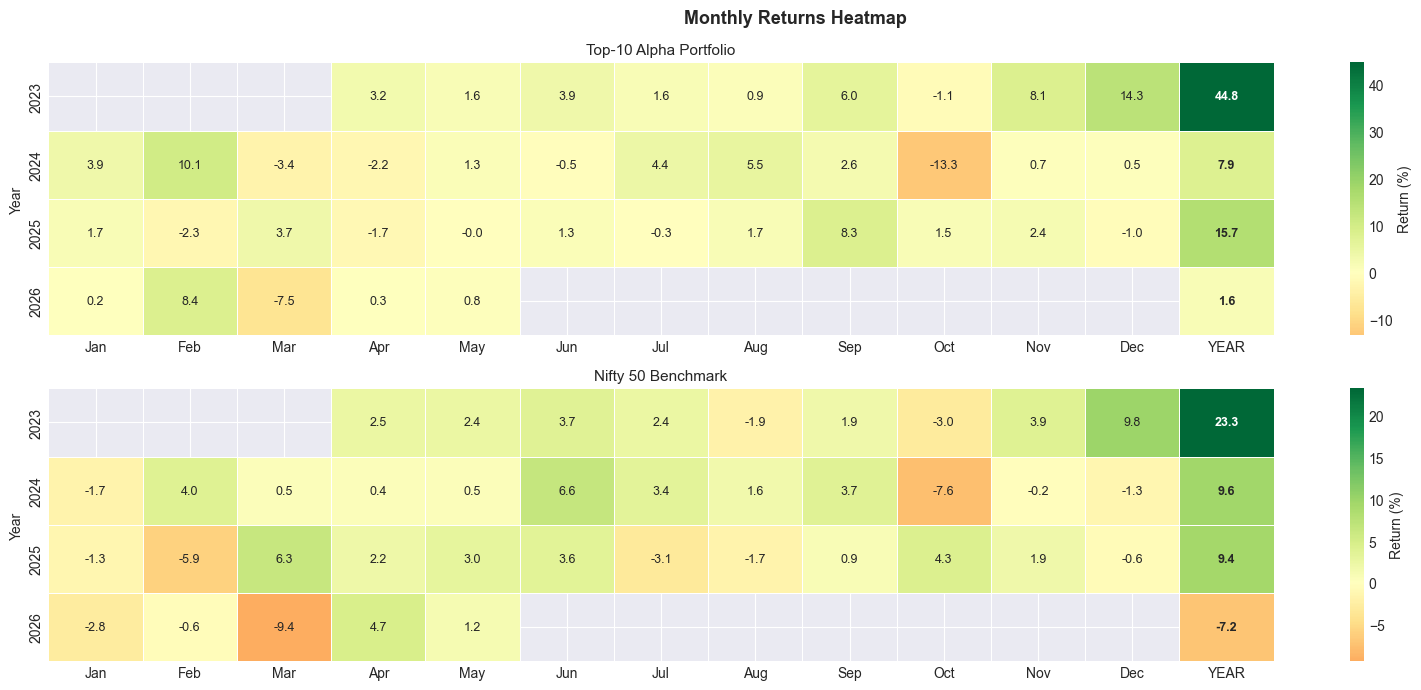


Portfolio monthly returns (%):


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,YEAR
Year,,,,,,,,,,,,,
2023,,,,3.200000,1.600000,3.900000,1.600000,0.900000,6.000000,-1.100000,8.100000,14.300000,44.800000
2024,3.900000,10.100000,-3.400000,-2.200000,1.300000,-0.500000,4.400000,5.500000,2.600000,-13.300000,0.700000,0.500000,7.900000
2025,1.700000,-2.300000,3.700000,-1.700000,-0.000000,1.300000,-0.300000,1.700000,8.300000,1.500000,2.400000,-1.000000,15.700000
2026,0.200000,8.400000,-7.500000,0.300000,0.800000,,,,,,,,1.600000


In [11]:
# ── Monthly returns heatmap ──────────────────────────────────────────────────
# Compound weekly returns into monthly returns
monthly_port  = results_df["Portfolio"].resample("ME").apply(lambda r: (1 + r).prod() - 1)
monthly_bench = results_df["Benchmark"].resample("ME").apply(lambda r: (1 + r).prod() - 1)

# Pivot into Year × Month grid
def to_heatmap(monthly):
    df = monthly.to_frame("ret")
    df["Year"]  = df.index.year
    df["Month"] = df.index.month
    return df.pivot(index="Year", columns="Month", values="ret")

port_grid  = to_heatmap(monthly_port)
bench_grid = to_heatmap(monthly_bench)

month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
port_grid.columns  = [month_names[m-1] for m in port_grid.columns]
bench_grid.columns = [month_names[m-1] for m in bench_grid.columns]

# Add full-year return column
port_grid["YEAR"]  = monthly_port.groupby(monthly_port.index.year).apply(lambda r: (1+r).prod()-1).values
bench_grid["YEAR"] = monthly_bench.groupby(monthly_bench.index.year).apply(lambda r: (1+r).prod()-1).values

fig, axes = plt.subplots(2, 1, figsize=(16, 7))
fig.suptitle("Monthly Returns Heatmap", fontsize=13, fontweight="bold")

for ax, grid, title in [
    (axes[0], port_grid,  "Top-10 Alpha Portfolio"),
    (axes[1], bench_grid, "Nifty 50 Benchmark"),
]:
    sns.heatmap(
        grid * 100,
        ax=ax, annot=True, fmt=".1f", center=0,
        cmap="RdYlGn", linewidths=0.5, linecolor="white",
        cbar_kws={"label": "Return (%)"},
        annot_kws={"size": 9},
    )
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Year")
    ax.set_xlabel("")
    # Bold the YEAR column
    for text in ax.texts:
        col_idx = int(text.get_position()[0])
        if col_idx == len(grid.columns) - 1:
            text.set_fontweight("bold")

plt.tight_layout()
plt.show()

# ── Monthly return table (numbers only) ─────────────────────────────────────
print("\nPortfolio monthly returns (%):")
display((port_grid * 100).round(1).fillna("").style.background_gradient(cmap="RdYlGn", axis=None, vmin=-10, vmax=10))